# LSTM with aspect attention

Tunes a bidirectional LSTM with aspect-driven attention on a validation split, keeps the best setting and scores the official test file once. The `conflict` label is dropped, as in the usual SemEval-2014 protocol. The LSTM starts from random word vectors, so it is a baseline: read its numbers against the majority-class accuracy printed by the data notebook, not on their own.

## Setup

Run this on a Colab GPU runtime (*Runtime → Change runtime type → GPU*). The cell clones the repository, installs the dependencies and checks the environment. Colab keeps its own `torch`, so it is left as it is.

In [1]:
import os

if not os.path.isdir("aspect-based-sentiment-analysis"):
    !git clone -q https://github.com/Shivam-Shukla0/aspect-based-sentiment-analysis.git
%cd aspect-based-sentiment-analysis
!pip install -q -r requirements.txt
!pip install -q -e . --no-deps
!python -m scripts.verify_environment --require-gpu

/content/run/aspect-based-sentiment-analysis


  Installing build dependencies ... done


  Checking if build backend supports build_editable ... done


  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done


  Building editable for absa (pyproject.toml) ... done


python          3.13.16
numpy           2.4.6
pandas          2.2.3
scikit-learn    1.6.1
lxml            6.1.3
torch           2.14.1+cu130
transformers    5.22.1
accelerate      1.15.0
sentencepiece   0.2.2
matplotlib      3.10.0
flask           3.1.3
absa            0.1.0
device          NVIDIA L4 (CUDA 13.0, 1 device)
environment ok


## Data

The official SemEval-2014 Task 4 files are distributed through the ILSP Metashare repository and need an account and acceptance of its licence (see `data/README.md`). This cell uses those files when they are in Google Drive (set `USE_DRIVE = True` after mounting Drive), and otherwise downloads the same four files from a public Hugging Face mirror of the dataset. The mirror did not come through the official route, so the file checksums are printed and the report states this limitation. Nothing in `data/` is committed to Git.

In [2]:
from pathlib import Path

USE_DRIVE = False  # True: copy the official files from DRIVE_DIR (mount Drive first)
DRIVE_DIR = Path("/content/drive/MyDrive/absa/semeval2014")
MIRROR = "https://huggingface.co/datasets/alexcadillon/SemEval2014Task4/resolve/main"
TRAIN = "SemEval%2714-ABSA-TrainData_v2%20%26%20AnnotationGuidelines"
FILES = {
    "Laptop_Train_v2.xml": (f"{MIRROR}/{TRAIN}/Laptop_Train_v2.xml", "laptop", "train"),
    "Restaurants_Train_v2.xml": (
        f"{MIRROR}/{TRAIN}/Restaurants_Train_v2.xml",
        "restaurant",
        "train",
    ),
    "Laptops_Test_Gold.xml": (
        f"{MIRROR}/ABSA_Gold_TestData/Laptops_Test_Gold.xml",
        "laptop",
        "test",
    ),
    "Restaurants_Test_Gold.xml": (
        f"{MIRROR}/ABSA_Gold_TestData/Restaurants_Test_Gold.xml",
        "restaurant",
        "test",
    ),
}
Path("data/raw").mkdir(parents=True, exist_ok=True)
for name, (url, domain, split) in FILES.items():
    if USE_DRIVE:
        !cp "{DRIVE_DIR / name}" data/raw/
    else:
        !curl -sL -o data/raw/{name} "{url}"
    !python -m scripts.build_processed data/raw/{name} --domain {domain} --split {split} > /dev/null
!sha256sum data/raw/*.xml
!wc -l data/processed/*.jsonl

aa3a30c9dd7e0eacf9b69e898eb4118a36c1b4f391a30a08dfc41a38d8b8745b  data/raw/Laptops_Test_Gold.xml
efec2ed73b4efb83b47c697114d800149c558118884afa80362a6e975ba7248c  data/raw/Laptop_Train_v2.xml
f21509cfa37e16534cd5b2da043be487355b64ef48fe8d6aaacaeca6b49cc0fb  data/raw/Restaurants_Test_Gold.xml
223601da1bded6caa4ef9cf91a7007578141ca6d8ed50d5a5c217565f89d2fc5  data/raw/Restaurants_Train_v2.xml


    654 data/processed/laptop_test.jsonl
    378 data/processed/laptop_test_no_aspect.jsonl
   2358 data/processed/laptop_train.jsonl
   1557 data/processed/laptop_train_no_aspect.jsonl
   1134 data/processed/restaurant_test.jsonl
    194 data/processed/restaurant_test_no_aspect.jsonl
   3693 data/processed/restaurant_train.jsonl
   1020 data/processed/restaurant_train_no_aspect.jsonl
  10988 total


## Train and evaluate

A small grid over dropout and learning rate. Every setting, and its validation score, is written to `outputs/lstm_<domain>/summary.json`; the test file is read only after the setting is chosen.

In [3]:
for domain in ("laptop", "restaurant"):
    !python -m scripts.train_lstm --domain {domain} --output-dir outputs/lstm_{domain} --hidden 128 --lr 0.001 0.003 --dropout 0.0 0.3 0.5 --weighting off --epochs 40 | tail -n 2

run 5: {'embedding_dim': 100, 'hidden_size': 128, 'num_layers': 1, 'dropout': 0.5, 'bidirectional': True, 'min_freq': 1, 'batch_size': 32, 'learning_rate': 0.003, 'epochs': 40, 'val_fraction': 0.2, 'seed': 42, 'class_weighting': False, 'device': 'auto', 'drop_conflict': True} val macro F1 0.6071
laptop: chosen hidden=128 lr=0.001 dropout=0.5 weighted=False; test accuracy 0.5987 macro F1 0.5082


run 5: {'embedding_dim': 100, 'hidden_size': 128, 'num_layers': 1, 'dropout': 0.5, 'bidirectional': True, 'min_freq': 1, 'batch_size': 32, 'learning_rate': 0.003, 'epochs': 40, 'val_fraction': 0.2, 'seed': 42, 'class_weighting': False, 'device': 'auto', 'drop_conflict': True} val macro F1 0.5821
restaurant: chosen hidden=128 lr=0.001 dropout=0.5 weighted=False; test accuracy 0.7152 macro F1 0.5729


## Results

In [4]:
import json

import pandas as pd

rows = []
for domain in ("laptop", "restaurant"):
    summary = json.load(open(f"outputs/lstm_{domain}/summary.json"))
    report = json.load(open(f"outputs/lstm_{domain}/test_report.json"))
    print(domain, "- validation macro F1 per setting:")
    for run in summary["runs"]:
        print(
            "   ",
            {k: v for k, v in run.items() if k != "config"}
            | {
                k: run["config"][k]
                for k in ("hidden_size", "learning_rate", "dropout")
                if "config" in run
            },
        )
    for cls in report["metrics"]["per_class"]:
        rows.append(
            {
                "domain": domain,
                **{k: cls[k] for k in ("label", "precision", "recall", "f1", "support")},
            }
        )
    print(
        f"   TEST accuracy {summary['test_accuracy']:.3f}  macro F1 {summary['test_macro_f1']:.3f}  ({summary['test_records']} records)"
    )
pd.DataFrame(rows).round(3)

laptop - validation macro F1 per setting:
    {'best_epoch': 40, 'val_macro_f1': 0.5770616978815161, 'hidden_size': 128, 'learning_rate': 0.001, 'dropout': 0.0}
    {'best_epoch': 26, 'val_macro_f1': 0.6016603197973468, 'hidden_size': 128, 'learning_rate': 0.001, 'dropout': 0.3}
    {'best_epoch': 34, 'val_macro_f1': 0.6077704028751388, 'hidden_size': 128, 'learning_rate': 0.001, 'dropout': 0.5}
    {'best_epoch': 19, 'val_macro_f1': 0.5772802595682329, 'hidden_size': 128, 'learning_rate': 0.003, 'dropout': 0.0}
    {'best_epoch': 20, 'val_macro_f1': 0.5988863472249575, 'hidden_size': 128, 'learning_rate': 0.003, 'dropout': 0.3}
    {'best_epoch': 23, 'val_macro_f1': 0.6071286367443329, 'hidden_size': 128, 'learning_rate': 0.003, 'dropout': 0.5}
   TEST accuracy 0.599  macro F1 0.508  (638 records)
restaurant - validation macro F1 per setting:
    {'best_epoch': 38, 'val_macro_f1': 0.569622887197004, 'hidden_size': 128, 'learning_rate': 0.001, 'dropout': 0.0}
    {'best_epoch': 20, 'va

,domain,label,precision,recall,f1,support
0,laptop,positive,0.784,0.754,0.768,341
1,laptop,negative,0.377,0.758,0.504,128
2,laptop,neutral,0.528,0.166,0.252,169
3,restaurant,positive,0.773,0.897,0.830,728
4,restaurant,negative,0.615,0.423,0.502,196
5,restaurant,neutral,0.464,0.332,0.387,196


## Confusion matrices

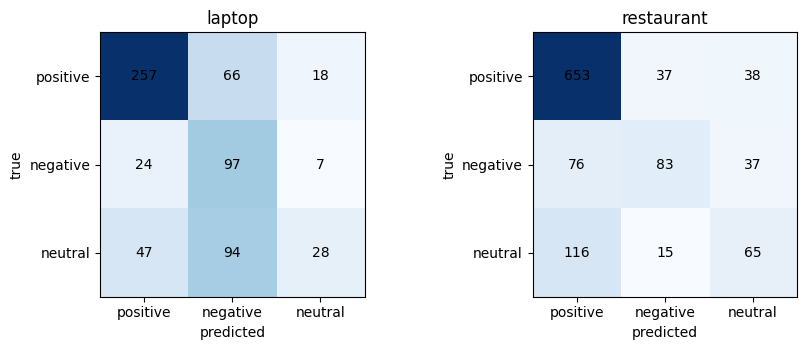

In [5]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, domain in zip(axes, ("laptop", "restaurant")):
    report = json.load(open(f"outputs/lstm_{domain}/test_report.json"))
    matrix = np.array(report["confusion_matrix"])
    ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(len(report["labels"])), report["labels"])
    ax.set_yticks(range(len(report["labels"])), report["labels"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(domain)
    for (i, j), value in np.ndenumerate(matrix):
        ax.text(j, i, int(value), ha="center", va="center")
plt.tight_layout()
plt.show()